In [1]:
%load_ext autoreload
%autoreload 2

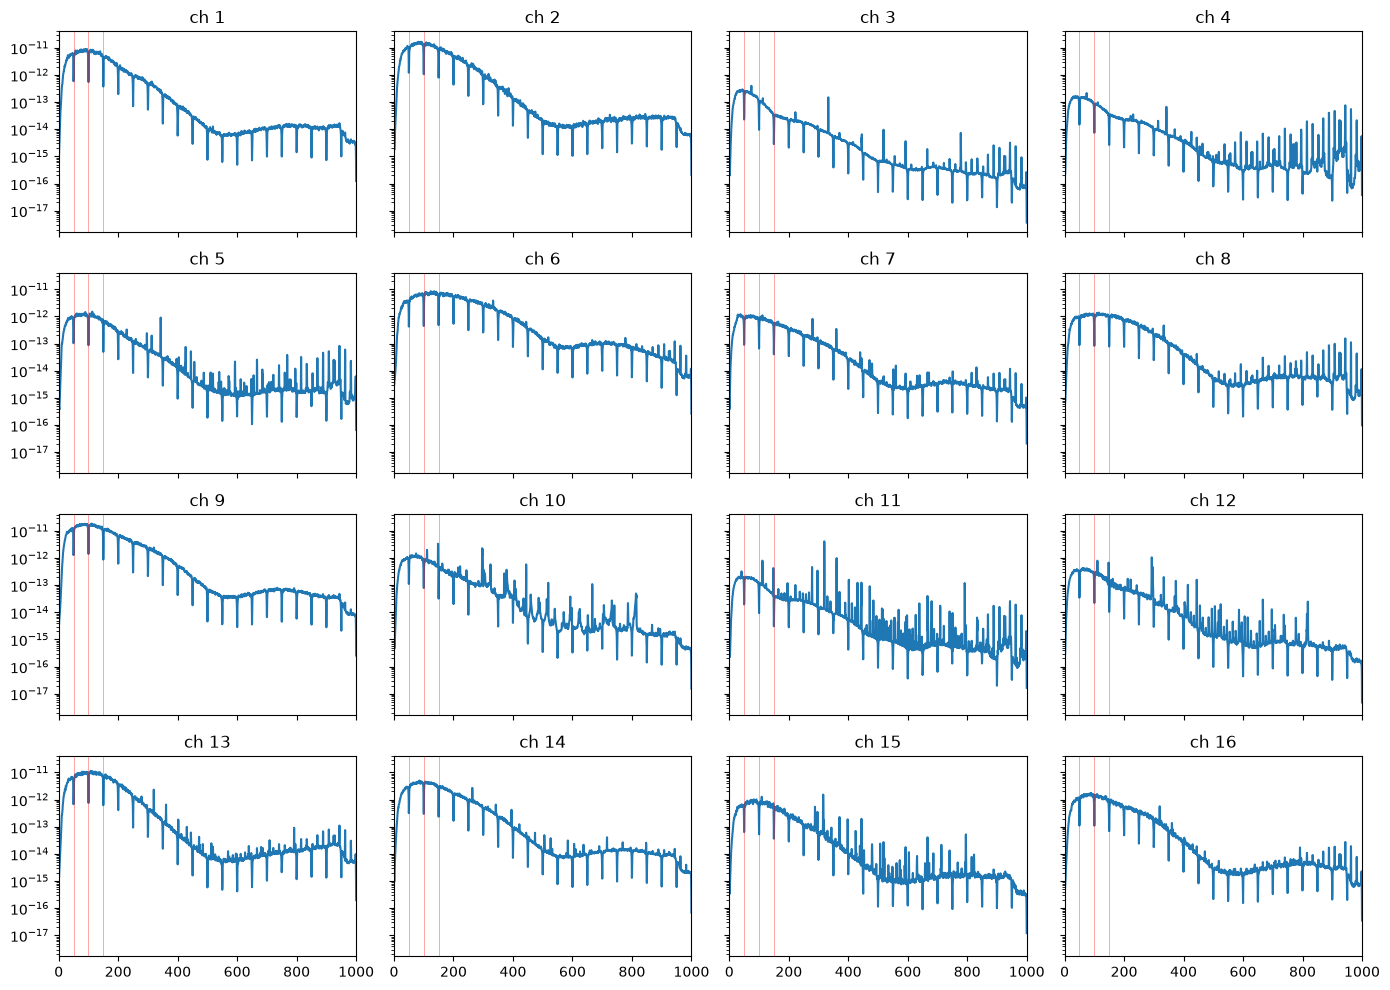

ch 1  rest   12.05 uV   move   46.60 uV   ratio   3.9
ch 2  rest   26.65 uV   move   61.03 uV   ratio   2.3
ch 3  rest    3.77 uV   move    6.10 uV   ratio   1.6
ch 4  rest    3.71 uV   move    4.91 uV   ratio   1.3
ch 5  rest    5.62 uV   move   17.61 uV   ratio   3.1
ch 6  rest    8.76 uV   move   57.90 uV   ratio   6.6
ch 7  rest    5.44 uV   move   17.62 uV   ratio   3.2
ch 8  rest    9.19 uV   move   20.43 uV   ratio   2.2
ch 9  rest   29.00 uV   move   69.90 uV   ratio   2.4
ch10  rest    8.31 uV   move   16.46 uV   ratio   2.0
ch11  rest    5.17 uV   move    5.89 uV   ratio   1.1
ch12  rest    5.47 uV   move    8.76 uV   ratio   1.6
ch13  rest   11.24 uV   move   54.30 uV   ratio   4.8
ch14  rest   14.44 uV   move   34.99 uV   ratio   2.4
ch15  rest    3.90 uV   move   15.92 uV   ratio   4.1
ch16  rest    6.25 uV   move   21.06 uV   ratio   3.4


In [1]:
import numpy as np, scipy.io as sio, matplotlib.pyplot as plt
from scipy.signal import welch
fs = 2000
d = sio.loadmat(r"D:\emg-project\data\raw\DB8\S1_E1_A1.mat")
emg = d["emg"].astype(np.float64)
restim = d["restimulus"].ravel()

# 1. Power spectrum of every channel (red lines = 50 Hz mains and its harmonics)
f, P = welch(emg, fs=fs, nperseg=4096, axis=0)
fig, axes = plt.subplots(4, 4, figsize=(14, 10), sharex=True, sharey=True)
for ch, ax in enumerate(axes.ravel()):
    ax.semilogy(f, P[:, ch]); ax.set_title(f"ch {ch+1}")
    for x in (50, 100, 150): ax.axvline(x, color="r", lw=0.5, alpha=0.5)
plt.xlim(0, 1000); plt.tight_layout(); plt.show()

# 2. Signal size at rest vs during movement, per channel
rest = np.sqrt((emg[restim == 0]**2).mean(axis=0))
move = np.sqrt((emg[restim > 0]**2).mean(axis=0))
for ch in range(16):
    print(f"ch{ch+1:2d}  rest {rest[ch]*1e6:7.2f} uV   move {move[ch]*1e6:7.2f} uV   ratio {move[ch]/rest[ch]:5.1f}")

In [1]:
%load_ext autoreload
%autoreload 2
import sys; sys.path.append(r"D:\emg-project\src")
import numpy as np
from emgproc import load, clean

for s in (1, 11, 12):
    emg, glove, rs, rr = load(rf"D:\emg-project\data\raw\DB8\S{s}_E1_A1.mat")
    x = clean(emg); r = rs[::2]                  # labels at the same 1000 Hz rate as x
    rest = np.sqrt((x[r == 0]**2).mean(axis=0))
    move = np.sqrt((x[r > 0]**2).mean(axis=0))
    print(f"S{s:2d} move/rest ratio per channel:", np.round(move / rest, 1))

S 1 move/rest ratio per channel: [3.9 2.3 1.6 1.4 3.2 6.7 3.3 2.2 2.4 2.  1.1 1.6 4.9 2.4 4.2 3.4]


C:\Users\admin\AppData\Local\Temp\ipykernel_7504\3189341695.py:12: RuntimeWarning: invalid value encountered in divide
  print(f"S{s:2d} move/rest ratio per channel:", np.round(move / rest, 1))


S11 move/rest ratio per channel: [3.  2.7 1.8 2.4 6.4 6.6 5.7 6.4 2.7 2.3 2.3 4.9 4.3 nan nan nan]
S12 move/rest ratio per channel: [18.1  5.9  5.3  4.1 19.  28.3 16.7 21.1  6.4  5.9  2.9  7.   nan  nan
  nan  nan]
